# PVWatts generation from explicit PV inputs

Use the optional PySAM backend with the same checksum-verified weather as the building model.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, PySAM.

## Understanding the API in this lesson

`PVSpec` describes a system's DC capacity, tilt, azimuth, losses and inverter settings. `RenewablesSpec` groups systems; `run_pvwatts(pv, climate)` explicitly invokes the optional PySAM backend and returns generation arrays and summary metrics.

PV generation is an AC output stream, not thermal demand or automatically avoided grid energy. The workflow diagram helps locate this distinction at the output stage. This API does not place panels on the rendered roof, infer usable roof area or translate the geometry viewer's neighbour meshes into detailed PV shading.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### PV forcing, design and output

The conceptual inputs converge in PVWatts: weather is not transformed into PVSpec. The calendar and seasonal bars below show computed generation. Generation alone is not self-consumption or avoided purchased electricity; those require coincident demand and an explicit balance. Roof geometry does not automatically establish usable PV capacity.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

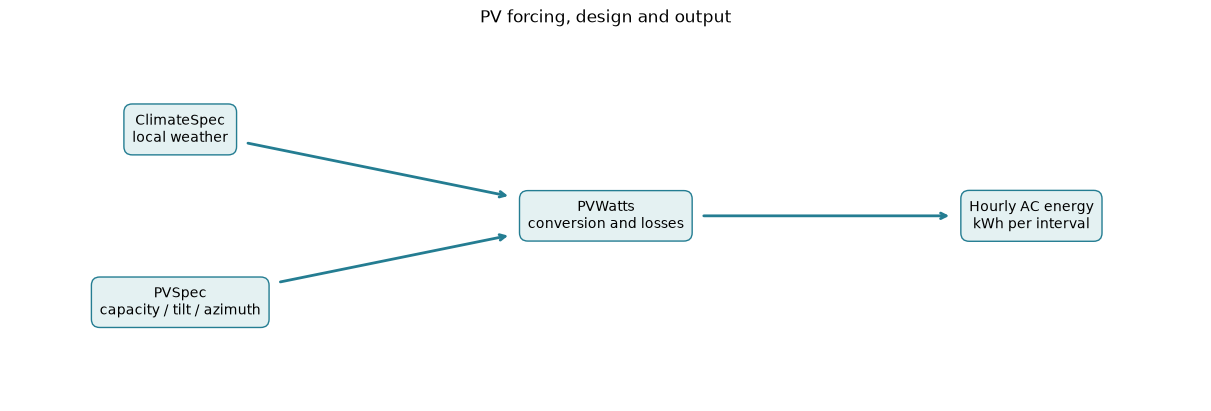

In [2]:
from demo.support.common import flow
flow(['ClimateSpec\nlocal weather', 'PVSpec\ncapacity / tilt / azimuth', 'PVWatts\nconversion and losses', 'Hourly AC energy\nkWh per interval'], 'PV forcing, design and output', figsize=(12, 4), converge=True)

## Define the PV system

DC nameplate capacity, tilt, azimuth and losses are explicit inputs. This example does not infer usable roof area or perform detailed neighbouring-building PV shading.

### Read the code and output

South-facing azimuth is 180° in this specification. DC capacity is the installed nameplate power, while the inverter and losses shape AC generation. The table is the complete input evidence for the scenario; no measured roof survey is implied by creating a `PVSpec`.

In [3]:
pv=PVSpec(dc_capacity_kw=5,tilt_deg=30,azimuth_deg=180)
renewables=RenewablesSpec(pv_systems=(pv,))
climate=climate_from_epw(epw())
table(pv.model_dump())
assert renewables.pv_systems[0]==pv

,field,value
0,dc_capacity_kw,5.0
1,tilt_deg,30.0
2,azimuth_deg,180.0
3,dc_ac_ratio,1.15
4,inverter_efficiency_pct,96
5,system_losses_pct,14.08
6,array_type,1
7,module_type,0
8,ground_coverage_ratio,0.4


## Run the real backend

PVWatts returns hourly AC generation in kWh. Reconcile it with the annual value before combining it with other result streams.

### Read the code and output

The heatmap shows daylight and seasonal timing in generated interval energy. Finite and nonnegative values are necessary data-quality checks. PVWatts also validates the annual/hourly energy reconciliation internally. Keep the weather checksum with the system inputs because generation depends on both.

,field,value
0,pv_generation_kwh,4638.764764303692
1,capacity_factor,0.10590787133113451


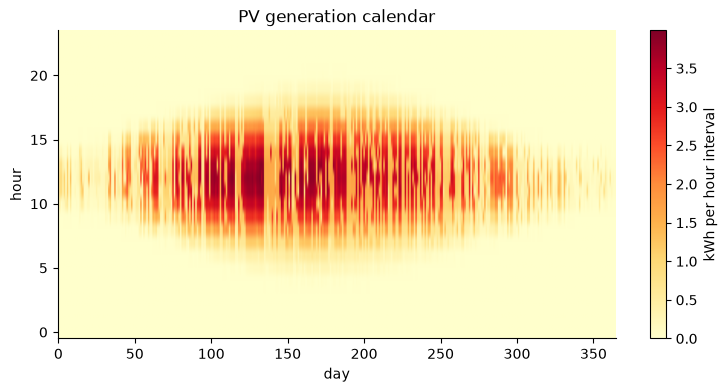

In [4]:
generation=run_pvwatts(pv,climate)
hourly=np.asarray(generation["pv_hourly_kwh"])
assert len(hourly)==climate.hours_in_year
assert np.all(np.isfinite(hourly)) and np.all(hourly>=0)
table({k:v for k,v in generation.items() if k!="pv_hourly_kwh"})
fig, ax = plt.subplots(figsize=(9, 4))
plt.imshow(hourly.reshape(-1,24).T,aspect="auto",origin="lower",cmap="YlOrRd"); plt.colorbar(label="kWh per hour interval"); plt.xlabel("day"); plt.ylabel("hour"); plt.title("PV generation calendar"); plt.show(); plt.close(fig)

## Compare orientation and seasonal generation

Keep capacity and climate fixed. A generation estimate is not self-consumption, avoided grid energy or economic payback.

### Read the code and output

The azimuth comparison keeps capacity, tilt and weather fixed, which makes orientation the intended sensitivity. Its annual totals do not reveal how much electricity is consumed on site. Self-consumption needs a compatible electrical-demand time series and an explicit matching calculation outside this example.

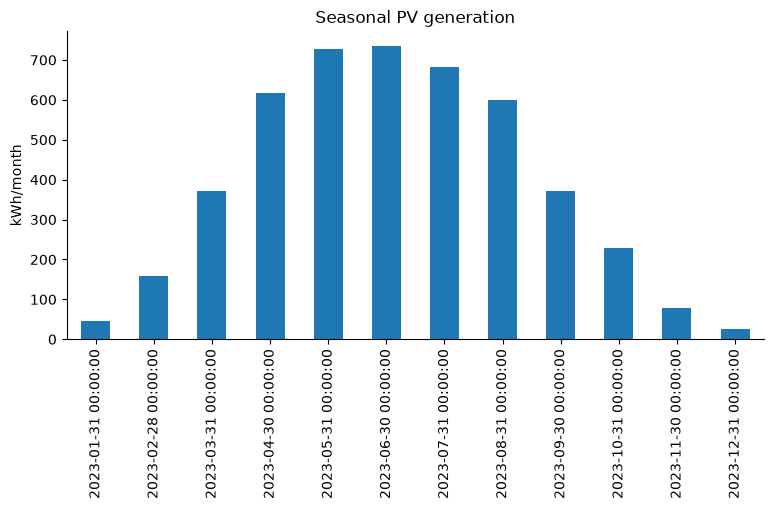

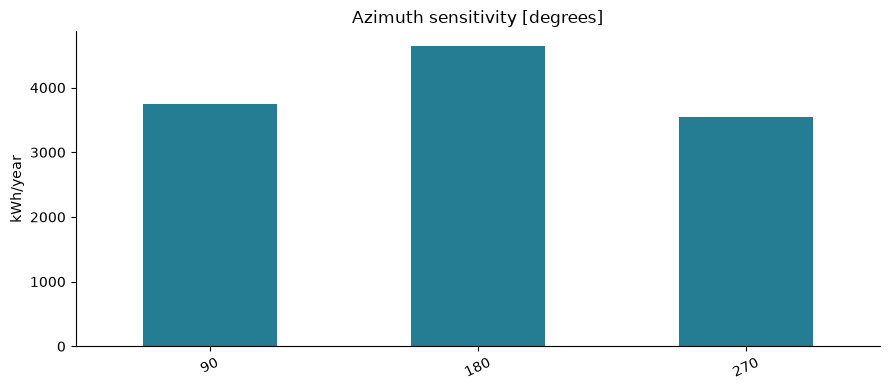

In [5]:
from epsm_core.weather import hourly_axis
series=pd.Series(hourly,index=pd.to_datetime(hourly_axis(climate.calendar_year)))
fig, ax = plt.subplots(figsize=(9, 4))
series.resample("ME").sum().plot.bar(ax=ax, ylabel="kWh/month",title="Seasonal PV generation"); plt.show(); plt.close(fig)
outputs={str(az):float(np.sum(run_pvwatts(pv.updated(azimuth_deg=az),climate)["pv_hourly_kwh"])) for az in [90,180,270]}
bars(outputs,"kWh/year","Azimuth sensitivity [degrees]")

## Interpretation and next experiment

Keep PV generation separate from building thermal demands. Roof suitability, self-consumption and economic assessment require additional caller-owned assumptions.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.